# 01 · Simulation audit (v2 world)

> **Independent educational simulation. Not an airline system or an approved maintenance, airworthiness or dispatch tool.** Falcon Hub Airways is fictional and every airline number below is SIMULATED by this repo's code: a simulated planning snapshot, not operator data. Provenance tags: **REAL** (public data), **DERIVED** (computed by code), **ASSUMED** (a config planning assumption), **SIMULATED** (simulator output).

**Why this notebook exists.** Every later result (forecasts, policies, the capital frontier) is only as credible as the simulated world it runs on. A hiring manager, or a sceptical materials planner, should be able to check five things before trusting any of it:

1. the v2 realism corrections are really in the data (type-specific parts, hypothetical rectification windows, planned brake changes, no-fault-found, AOG recovery routes instead of an outright AOG buy);
2. the legacy policy P0 was calibrated against a band fixed **before** any P1/P2 result existed, and we can see how that band was chosen;
3. P0 sits where it should in each of the three worlds (central, low stress, high stress);
4. the books balance: stock, owned serials, borrowed units, robbery donors, requests and material AOG hours are conserved;
5. the four *planted situations* (PS1–PS4) can be found in the public history without opening the hidden truth.

A v1 world was archived after a domain review; see `archive/v1`. Everything here reads the public history only (`data/processed/grounded.duckdb`, weeks 0–103, policy P0) plus the calibration and holdout summaries in `outputs/`. No hidden truth table is opened.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))            # notebooks/_style.py
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from _style import *                            # palette, ROOT, stamp(), aed_m(), load_json(), ci()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("project root:", ROOT)
import duckdb
con = duckdb.connect(str(ROOT / "data" / "processed" / "grounded.duckdb"), read_only=True)
q = lambda sql: con.execute(sql).df()
sqlf = lambda name: q(open(ROOT / "sql" / name).read())
parts = load_json("docs/data/parts.json")["parts"]
PS = {p["planted"]: p["pn"] for p in parts if p["planted"]}      # planted tags are public master-data labels
cfg_cal = load_json("outputs/calibration/p0_history_summary.json")
print("planted situations:", PS)
print(q("select count(*) as n from information_schema.tables").n[0], "history views available")

project root: /Users/akashgajjar/grounded-no-more
planted situations: {'PS3': 'GN-20-C040', 'PS4': 'GN-33-E033', 'PS1': 'GN-32-R014', 'PS2': 'GN-34-R018'}
20 history views available


## 1. What changed in v2, checked in the data

The v2 world fixes the realism problems found in the domain review. These are model corrections chosen before any v2 result existed, not tuning. Each line below is checked against the history tables rather than taken on trust:

| Area | v2 rule | Check below |
|---|---|---|
| Catalogue | 120 hand-curated PNs (45 C / 35 E / 40 R). Applicability is type-exclusive; only common items (masks, lamps, battery packs, hardware, fluids) fit both types | class counts, PNs on both types |
| Rectification windows (hypothetical) | D0 only where no plausible MEL relief exists; no D0 consumables; servicing fluids are `NONE` and never drive AOG. D3/D10 are simplified analogues of MEL repair-interval categories B and C, not operator MEL decisions | window × class table, AOG hours on `NONE` |
| Brakes | Type-specific and `wear_planned`: changed at AUH at notice (5–10 days ahead). Cost-per-landing contracts are not modelled. Residual brake downtime only occurs when AUH is short and the exchange fails | brake changes by sourcing route |
| No-fault-found | Avionics, computers, valves, pumps and probes come back NFF 10–40% of the time (short, cheap shop visit, never condemned) | NFF share of repair orders |
| AOG recovery routes | No outright AOG buy. Rotables: local borrow at outstations, robbery at AUH (engineering/quality approval required), exchange/loan. C/E: local buy. Odds and response times are ASSUMED (`config/assumptions.yaml: aog_sourcing`) | requests filled by each route |
| AOG accounting | An event counts only if the part is late; it runs from need + window to release to service, including fitting time | section 4 |

In [2]:
cls = q("select part_class, count(*) as pns from part_master group by 1 order by 1")
both = q("select count(*) as n from (select pn from part_applicability group by pn having count(distinct archetype) = 2)").n[0]
both_fam = q("""select pm.family, count(*) as pns from part_master pm where pn in
               (select pn from part_applicability group by pn having count(distinct archetype) = 2) group by 1 order by 2 desc""")
print("PNs by class:", dict(zip(cls.part_class, cls.pns)), f"| on both types: {both} of {cls.pns.sum()} ({both / cls.pns.sum():.0%})")
print("families on both types:", ", ".join(both_fam.family))
win = q("select deadline_class as window, part_class, count(*) as pns from part_master group by all")
display(win.pivot(index="window", columns="part_class", values="pns").fillna(0).astype(int).reindex(["D0", "D3", "D10", "NONE"]))
none_aog = q("""select count(*) as n from aog_events a, unnest(string_split(a.pns, ',')) as t(pn)
                join part_master pm on pm.pn = trim(t.pn) where pm.deadline_class = 'NONE'""").n[0]
d0_cons = q("select count(*) as n from part_master where part_class = 'C' and deadline_class = 'D0'").n[0]
nff = q("""select pm.part_class, count(*) as ros, avg(case when ro.nff then 1.0 else 0.0 end) as nff_share
           from repair_orders ro join part_master pm using (pn) where ro.removal_id is not null group by 1""")
print(f"D0 consumables: {d0_cons} | AOG events involving a NONE (servicing fluid) PN: {none_aog}")
print("NFF share of rotable repair orders:", f"{nff.nff_share.iloc[0]:.1%} of {int(nff.ros.iloc[0]):,}")
assert d0_cons == 0 and none_aog == 0

PNs by class: {'C': 45, 'E': 35, 'R': 40} | on both types: 12 of 120 (10%)
families on both types: hardware, fluid, lamp, oxygen_mask, valve_small, light, battery_pack, crew_mask


part_class,C,E,R
window,,,
D0,0,3,10
D3,11,12,19
D10,31,20,11
NONE,3,0,0


D0 consumables: 0 | AOG events involving a NONE (servicing fluid) PN: 0
NFF share of rotable repair orders: 15.5% of 1,728


,pn,description,sourced_as,planned_changes,mean_notice_days,fitted_from_stock_on_the_day,mean_wait_after_due_h,downtime_events,downtime_hours
0,GN-32-R013,Carbon brake assembly (NB),planned_covered,80,7.3,80.0,0.0,0,0.0
1,GN-32-R013,Carbon brake assembly (NB),planned_transfer,10,7.1,10.0,0.0,0,0.0
2,GN-32-R013,Carbon brake assembly (NB),planned_loan,11,7.2,0.0,0.0,0,0.0
3,GN-32-R013,Carbon brake assembly (NB),robbery,1,9.5,0.0,78.0,1,83.0
4,GN-32-R036,Carbon brake assembly (WB),planned_covered,88,7.5,88.0,0.0,0,0.0
5,GN-32-R036,Carbon brake assembly (WB),planned_transfer,17,7.0,17.0,0.0,0,0.0
6,GN-32-R036,Carbon brake assembly (WB),planned_loan,6,7.7,0.0,0.0,0,0.0
7,GN-32-R036,Carbon brake assembly (WB),robbery,2,8.9,0.0,7.5,2,25.0
8,GN-32-R036,Carbon brake assembly (WB),none,1,6.2,0.0,45.0,1,50.0


,route,requests,mean_wait_h,approval_flagged
0,transfer,141,22.0,0.0
1,local_buy,69,133.6,0.0
2,exchange_loan,63,66.7,0.0
3,robbery,56,49.7,56.0
4,repair,53,68.4,0.0
5,purchase,13,70.4,0.0
6,local_borrow,8,26.8,0.0
7,unfilled at end,1,NaN,0.0


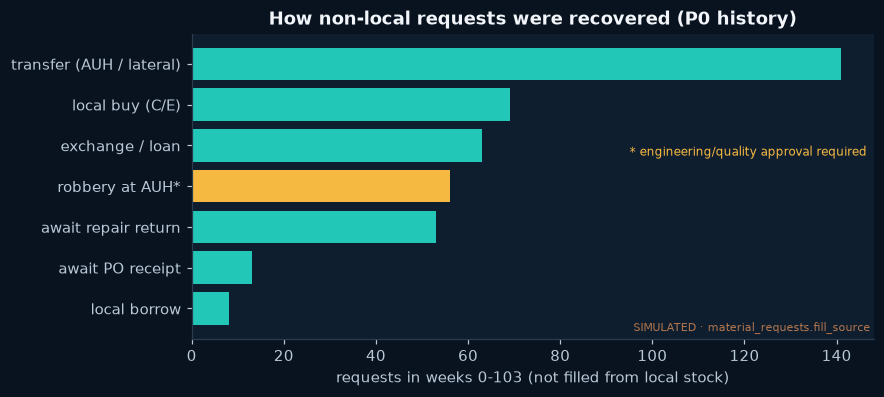

In [3]:
brakes = sqlf("12_brake_changes_sourced_at_notice.sql")
display(brakes)
routes = q("""select coalesce(fill_source, 'unfilled at end') as route, count(*) as requests,
              avg(filled_h - need_h) as mean_wait_h, sum(case when approval_flag is not null then 1 else 0 end) as approval_flagged
              from material_requests where fill_source not in ('local') or fill_source is null group by 1 order by 2 desc""")
display(routes.round(1))
fig, ax = plt.subplots(figsize=(8, 3.6))
r = routes[routes.route != "unfilled at end"]
lab = {"transfer": "transfer (AUH / lateral)", "robbery": "robbery at AUH*", "exchange_loan": "exchange / loan",
       "local_buy": "local buy (C/E)", "repair": "await repair return", "purchase": "await PO receipt", "local_borrow": "local borrow"}
ax.barh([lab.get(x, x) for x in r.route], r.requests, color=[AMBER if x == "robbery" else TEAL for x in r.route])
ax.invert_yaxis(); ax.set(xlabel="requests in weeks 0-103 (not filled from local stock)", title="How non-local requests were recovered (P0 history)")
ax.text(0.99, 0.6, "* engineering/quality approval required", transform=ax.transAxes, ha="right", color=AMBER, fontsize=8)
stamp(ax, "material_requests.fill_source"); plt.show()

Most brake changes are covered from AUH stock at the planned change; the rest use a transfer or an exchange/loan arranged at notice. Residual brake downtime only occurs when AUH is short and the exchange fails (the few `robbery` / `none` rows). Cost-per-landing brake contracts are not modelled. Robbery is used, and every robbery carries the approval flag: the simulation shows how often the desk relies on it, but it never treats it as a free route. Borrowed units never join the owned pool or the capital figure (checked in section 4).

## 2. Fleet, exposure and removals against the vendor quote

Exposure (flight hours FH and cycles FC) drives removals. Narrowbodies should fly shorter sectors (more cycles per hour) and widebodies longer ones. We then compare the removals the fleet actually saw with what the vendor-quoted MTBUR predicts for the same exposure. A ratio above 1 means the part is removed more often than quoted.

,archetype,tails,fh_per_tail_day,fc_per_tail_day,hours_per_cycle
0,narrowbody,24,10.55,4.24,2.49
1,widebody,16,14.50,2.44,5.95


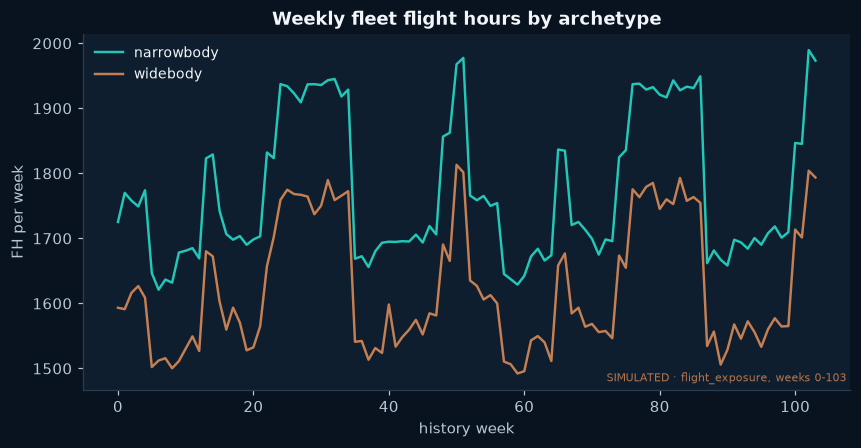

In [4]:
fleet = q("""
select am.archetype, count(distinct am.tail) as tails,
       sum(fe.fh) / count(distinct am.tail) / (104*7) as fh_per_tail_day,
       sum(fe.fc) / count(distinct am.tail) / (104*7) as fc_per_tail_day,
       sum(fe.fh) / sum(fe.fc) as hours_per_cycle
from flight_exposure fe join aircraft_master am using (tail) group by 1 order by 1""")
display(fleet.round(2))
weekly = q("""select fe.week, am.archetype, sum(fe.fh) as fh
              from flight_exposure fe join aircraft_master am using (tail) group by all order by 1""")
w = weekly.pivot(index="week", columns="archetype", values="fh")
fig, ax = plt.subplots()
ax.plot(w.index, w["narrowbody"], color=TEAL, lw=1.6, label="narrowbody")
ax.plot(w.index, w["widebody"], color=COPPER, lw=1.6, label="widebody")
ax.set(title="Weekly fleet flight hours by archetype", xlabel="history week", ylabel="FH per week")
ax.legend(frameon=False); stamp(ax, "flight_exposure, weeks 0-103"); plt.show()

73 R/E parts with removals; median actual/quoted removal ratio = 1.05


,count,25%,50%,75%
part_class,,,,
E,35.0,0.89,1.11,1.31
R,38.0,0.84,1.02,1.30


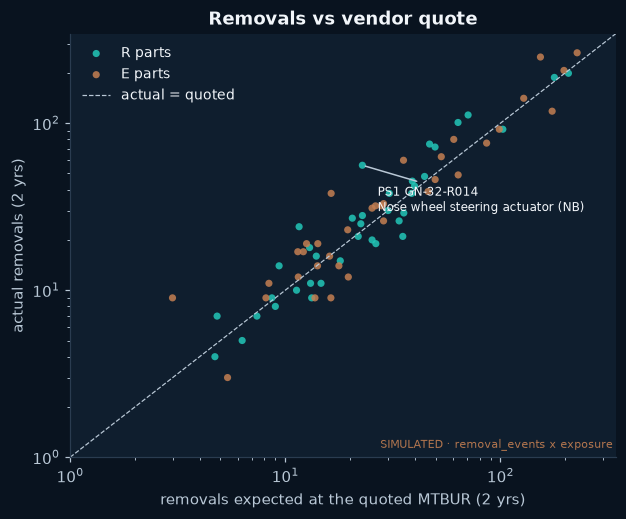

PS1 GN-32-R014: observed MTBUR 1,324 FC vs quoted 3,250 (2.45x)


In [5]:
rates = q(open(ROOT / "sql" / "10_removal_rate_vs_quoted.sql").read().replace("LIMIT 15", "").replace(
    "WHERE r.removals >= 10", "WHERE r.removals >= 1"))
rates["expected_at_quote"] = rates.exposure / rates.mtbur_quoted
rates["actual_vs_quote"] = rates.removals / rates.expected_at_quote
print(f"{len(rates)} R/E parts with removals; median actual/quoted removal ratio = {rates.actual_vs_quote.median():.2f}")
display(rates.groupby("part_class").actual_vs_quote.describe()[["count", "25%", "50%", "75%"]].round(2))
fig, ax = plt.subplots(figsize=(6.4, 5))
for c, col in (("R", TEAL), ("E", COPPER)):
    d = rates[rates.part_class == c]
    ax.scatter(d.expected_at_quote, d.removals, s=22, color=col, alpha=0.85, label=f"{c} parts", edgecolor="none")
lim = [1, rates[["expected_at_quote", "removals"]].max().max() * 1.3]
ax.plot(lim, lim, color=TITANIUM, lw=0.8, ls="--", label="actual = quoted")
ps1 = rates[rates.pn == PS["PS1"]].iloc[0]
ax.annotate(f"PS1 {ps1.pn}\n{ps1.description}", (ps1.expected_at_quote, ps1.removals), xytext=(10, -30),
            textcoords="offset points", color=ICE, fontsize=8, arrowprops=dict(arrowstyle="-", color=TITANIUM))
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="removals expected at the quoted MTBUR (2 yrs)",
       ylabel="actual removals (2 yrs)", title="Removals vs vendor quote")
ax.legend(frameon=False, loc="upper left"); stamp(ax, "removal_events x exposure"); plt.show()
print(f"PS1 {ps1.pn}: observed MTBUR {ps1.mtbur_observed:,.0f} {ps1.driver} vs quoted {ps1.mtbur_quoted:,.0f} ({ps1.quoted_vs_observed:.2f}x)")

After calibration the vendor quotes are only mildly optimistic on average, with part-specific scatter: a history-based planner still has an edge, but a quote-based planner is not a straw man. PS1, the nose wheel steering actuator, is the outlier the world was built to contain: it is removed far more often than quoted.

## 3. Calibration: diagnosis, band and the V1 choice

**Diagnosis first.** Before calibrating, a gap diagnosis compared P0's own on-paper availability with the simulated rotable fill (`outputs/calibration/v2_p0_gap_diagnosis.md`). It found two design mismatches and one bug, fixed as non-calibration corrections (V2-SIM-10..12). The main one: P0 sized its protection level on P(N ≤ S) while the engine measures immediate fill as P(N ≤ S − 1). Every other remaining gap was intended realism: optimistic quotes, outstation D0 demand that the legacy rule does not stock, and no-fault-found, which works in P0's favour.

In [6]:
gap = load_json("outputs/calibration/v2_p0_gap_diagnosis.json")
print(gap["status"])
print(f"P0 demand-weighted analytic availability at AUH: {gap['analytic_weighted_hub']['prefix']:.3f} before the fix "
      f"-> {gap['analytic_weighted_hub']['postfix']:.3f} after (target 0.90-0.95)")
ex = pd.DataFrame(gap["experiments_postfix"]).T[["rotable_fill", "rotable_fill_hub", "aog_hours_per_year_mean"]]
base = ex.loc["full (as built)"]
ex["fill_change_vs_as_built"] = ex.rotable_fill - base.rotable_fill
print("One-factor-at-a-time counterfactuals (diagnostic runs, after the fixes, before calibration and before V2-SIM-13..15):")
display(ex.sort_values("fill_change_vs_as_built", ascending=False).round(3))

diagnostic; fixes V2-SIM-10..12 applied; no calibration, no lock
P0 demand-weighted analytic availability at AUH: 0.872 before the fix -> 0.948 after (target 0.90-0.95)
One-factor-at-a-time counterfactuals (diagnostic runs, after the fixes, before calibration and before V2-SIM-13..15):


,rotable_fill,rotable_fill_hub,aog_hours_per_year_mean,fill_change_vs_as_built
ideal (P0 assumptions hold),0.943,0.943,2081.2,0.274
rates = quoted,0.848,0.942,2346.7,0.178
all rotable demand at AUH,0.770,0.770,4272.8,0.101
TAT mean = quoted,0.740,0.827,5377.6,0.071
no transport,0.682,0.761,5084.6,0.013
Poisson (no NB frailty),0.679,0.755,5535.8,0.010
no condemnation,0.671,0.749,5535.4,0.002
no shop queue,0.670,0.749,5486.4,0.001
deterministic TAT,0.670,0.748,5337.5,0.001
full (as built),0.669,0.747,5519.6,0.000


**The band (ASSUMED, chosen by the user after the diagnosis and before any P1/P2 result).** P0 network rotable immediate fill 0.78–0.85, material AOG 1,200–2,700 h/yr, 60–100 AOG events/yr: a legacy OEM-quote provisioning policy with no line-station units for low-volume D0 parts. Four candidate settings were measured in memory; the user's rule was *fewest changes that land inside the band*.

In [7]:
T = cfg_cal["targets"]
var = load_json("outputs/calibration/v2_p0_variants.json")
rows = []
for name, v in var.items():
    h, s = v["history"], v["selection_mean"]
    inside = all(T[k][0] <= h[k] <= T[k][1] and T[k][0] <= s[k] <= T[k][1] for k in T)
    rows.append(dict(variant=name, rot_fill_hist=h["rotable_immediate_fill_rate"], rot_fill_sel=s["rotable_immediate_fill_rate"],
                     aog_h_hist=h["aog_hours_per_year"], aog_h_sel=s["aog_hours_per_year"],
                     events_hist=h["aog_events_per_year"], events_sel=s["aog_events_per_year"], inside_band=inside))
vt = pd.DataFrame(rows); display(vt.round(3))
print("band:", T)
print("settings applied (V1, quote accuracy only):", {k: v for k, v in cfg_cal["settings_used"].items() if k not in ("generator.variants", "not_applied")})
print("not applied:", cfg_cal["settings_used"]["not_applied"])
print("stress worlds (true-MTBUR scalar only):", cfg_cal["settings_used"]["generator.variants"])
assert vt[vt.variant.str.startswith("V1")].inside_band.all() and vt.inside_band.sum() == 1

,variant,rot_fill_hist,rot_fill_sel,aog_h_hist,aog_h_sel,events_hist,events_sel,inside_band
0,V0 raw P0 (after A),0.678,0.673,1712.0,1907.2,97.0,90.4,False
1,V1 quote accuracy,0.815,0.809,1282.0,1434.8,74.0,72.0,True
2,V2 legacy line-kit,0.711,0.705,1245.5,1445.2,68.5,63.2,False
3,V3 = V1 + V2,0.832,0.830,1052.5,1142.4,59.0,53.6,False
4,V4 = V3 + AOG market (reference),0.831,0.830,911.5,975.6,57.0,52.2,False


band: {'rotable_immediate_fill_rate': [0.78, 0.85], 'aog_hours_per_year': [1200, 2700], 'aog_events_per_year': [60, 100]}
settings applied (V1, quote accuracy only): {'parts.quoted_mtbur_optimism': 1.1, 'parts.quoted_mtbur_noise_sd_log': 0.2, 'generator.quoted_tat_optimism': 0.95, 'generator.quoted_tat_noise_sd_log': 0.1}
not applied: ['AOG-market settings', 'line-station kit']
stress worlds (true-MTBUR scalar only): {'central': {'true_mtbur_scale': 1.0}, 'low_stress': {'true_mtbur_scale': 1.08}, 'high_stress': {'true_mtbur_scale': 0.96}}


V1 (tighter vendor quotes, nothing else) is the only candidate inside the band on both the history and the selection seeds. V3 and V4 overshoot below the AOG and event floors, and V2 (a line-station kit) misses on fill. The market and line-kit settings were therefore **not** applied. The calibration is locked (`outputs/freeze/calibration_lock.json`), and the lock test fails if the simulator or its config changes afterwards.

Below, the central-world history KPIs are recomputed straight from the history tables and compared with the locked summary.

In [8]:
hist = cfg_cal["variants"]["central"]["history"]
mine = q("""
select sum(case when immediate_fill then qty else 0 end) / sum(qty) as immediate_fill_rate,
       avg(case when pm.part_class = 'R' then case when immediate_fill then 1.0 else 0.0 end end) as rotable_immediate_fill_rate,
       (select sum(hours) / 2 from aog_events) as aog_hours_per_year,
       (select count(*) / 2 from aog_events) as aog_events_per_year
from material_requests r join part_master pm using (pn)""").iloc[0]
kt = pd.DataFrame([dict(kpi=k, band=T.get(k), locked_summary=hist[k], recomputed_here=mine[k]) for k in mine.index])
display(kt.round(4))
assert np.allclose(kt.recomputed_here, kt.locked_summary, rtol=1e-9)

,kpi,band,locked_summary,recomputed_here
0,immediate_fill_rate,None,0.9904,0.9904
1,rotable_immediate_fill_rate,"[0.78, 0.85]",0.8145,0.8145
2,aog_hours_per_year,"[1200, 2700]",1282.0000,1282.0000
3,aog_events_per_year,"[60, 100]",74.0000,74.0000


## 4. P0 in each world against the targets

The two stress worlds change only the true MTBUR and were placed at the ends of the band. One scalar cannot reach both ends of a two-sided band at once, so **the low-stress world reaches the AOG end while its fill stays inside the band, and the high-stress world reaches the fill end well before the AOG end, because fill binds first.** That is disclosed as it came out (the printout below gives the numbers). Columns: the history (seed 7), the 5 calibration selection seeds, the 20 policy-selection seeds 100–119 and the holdout P0 (seeds 2000–2019, never used in calibration).

In [9]:
ps = load_json("outputs/holdout/policy_summary.json")
sel20 = load_json("outputs/policies/selection_summary.json")
bc = pd.DataFrame(ps["by_class"])
rows = []
for wv in ["low_stress", "central", "high_stress"]:
    v = cfg_cal["variants"][wv]
    hp = ps["variants"][wv]["policies"]["P0"]
    rot_h = bc[(bc.variant == wv) & (bc.policy_id == "P0") & (bc.part_class == "R")].immediate_fill_rate.iloc[0]
    rows.append(dict(world=wv, true_mtbur_scale=v["true_mtbur_scale"], stress_target=v["stress_targets"],
                     rot_fill_history=v["history"]["rotable_immediate_fill_rate"], rot_fill_selection=v["selection_p0_mean"]["rotable_immediate_fill_rate"],
                     rot_fill_holdout=rot_h, aog_h_history=v["history"]["aog_hours_per_year"],
                     aog_h_selection=v["selection_p0_mean"]["aog_hours_per_year"], aog_h_sel20=sel20["variants"][wv]["policies"]["P0"]["aog_hours"]["mean"],
                     aog_h_holdout=hp["aog_hours"]["mean"],
                     events_history=v["history"]["aog_events_per_year"], events_holdout=hp["aog_events"]["mean"]))
pw = pd.DataFrame(rows).set_index("world"); display(pw.round(3))
lo_, hi_ = cfg_cal["variants"]["low_stress"], cfg_cal["variants"]["high_stress"]
pool = lambda v, k: (v["history"][k] + v["selection_p0_mean"][k]) / 2
print(f"low stress : AOG {pool(lo_, 'aog_hours_per_year'):,.0f} h/yr (target end {lo_['stress_targets']['aog_hours_per_year']:,}), "
      f"rotable fill {pool(lo_, 'rotable_immediate_fill_rate'):.3f} (history/selection average)")
print(f"high stress: rotable fill {pool(hi_, 'rotable_immediate_fill_rate'):.3f} (target end {hi_['stress_targets']['rotable_immediate_fill_rate']}), "
      f"AOG {pool(hi_, 'aog_hours_per_year'):,.0f} h/yr vs the {hi_['stress_targets']['aog_hours_per_year']:,} h end")

,true_mtbur_scale,stress_target,rot_fill_history,rot_fill_selection,rot_fill_holdout,aog_h_history,aog_h_selection,aog_h_sel20,aog_h_holdout,events_history,events_holdout
world,,,,,,,,,,,
low_stress,1.08,"{'aog_hours_per_year': 1200, 'rotable_immediat...",0.846,0.836,0.833,1123.0,1225.8,1378.25,1480.5,66.5,66.10
central,1.00,None,0.815,0.809,0.803,1282.0,1434.8,1727.35,1690.5,74.0,77.95
high_stress,0.96,"{'aog_hours_per_year': 2700, 'rotable_immediat...",0.780,0.781,0.769,1631.5,1558.4,1877.10,1825.0,84.5,84.10


low stress : AOG 1,174 h/yr (target end 1,200), rotable fill 0.841 (history/selection average)
high stress: rotable fill 0.781 (target end 0.78), AOG 1,595 h/yr vs the 2,700 h end


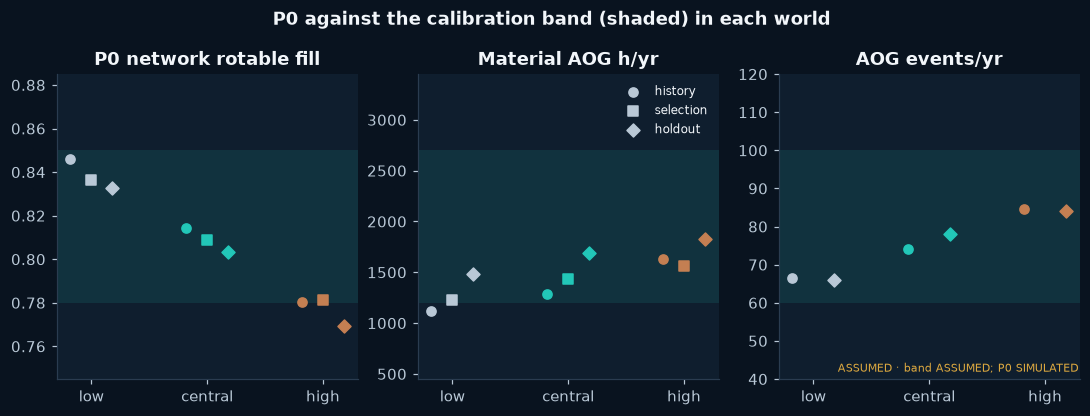

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
specs = [("rotable_immediate_fill_rate", "rot_fill", "P0 network rotable fill"), ("aog_hours_per_year", "aog_h", "Material AOG h/yr"),
         ("aog_events_per_year", "events", "AOG events/yr")]
wcol = {"low_stress": TITANIUM, "central": TEAL, "high_stress": COPPER}
for ax, (k, short, title) in zip(axes, specs):
    lo, hi = T[k]
    ax.axhspan(lo, hi, color=TEAL, alpha=0.12, lw=0)
    for i, wv in enumerate(pw.index):
        pts = [(c, pw.loc[wv, c]) for c in pw.columns if c.startswith(short + "_") and c != "aog_h_sel20"]
        for c, val in pts:
            j = ["history", "selection", "holdout"].index(c.split("_")[-1])
            ax.scatter(i + (j - 1) * 0.18, val, color=wcol[wv], marker=["o", "s", "D"][j], s=36, zorder=3,
                       label=c.split("_")[-1] if (i == 0 and k == "aog_hours_per_year") else None)
    pad = (hi - lo) * 0.5
    ax.set(xticks=range(3), xticklabels=["low", "central", "high"], title=title, ylim=(lo - pad, hi + pad))
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("P0 against the calibration band (shaded) in each world", color=ICE, fontweight="bold", y=1.04)
stamp(axes[-1], "band ASSUMED; P0 SIMULATED", "ASSUMED"); plt.show()

The central world sits inside all three bands on history, the calibration seeds and the holdout. Holdout AOG runs above the 5-seed calibration mean but agrees with the 20 policy-selection seeds, so the difference is seed noise in a small sample, not drift; the holdout stays inside the band.

## 5. Conservation checks

A simulator that loses or invents parts would make every downstream number meaningless. v2 adds borrowed units (exchange/loan, local borrow) and robbery donors, so the checks now separate **owned** serials from **borrowed** ones:

In [11]:
checks = []
def check(name, ok, detail):
    checks.append(dict(check=name, passed=bool(ok), detail=detail))

r = q("""with w as (select distinct week from stock_snapshots),
t as (select w.week, it.pn, it.station, sum(it.qty_delta) as oh
      from w join inventory_transactions it on it.t_h < (w.week + 1) * 168 group by all)
select count(*) as n, sum(case when coalesce(t.oh, 0) = s.on_hand then 1 else 0 end) as matched
from stock_snapshots s left join t using (week, pn, station)""").iloc[0]
check("on-hand = running sum of transactions (every pn x station x week)", r.n == r.matched, f"{int(r.matched):,}/{int(r.n):,} snapshot rows")

r = q("""select count(*) as bad from (select serial, since_h, lag(until_h) over (partition by serial order by since_h) prev
         from serialised_components) where prev is not null and prev <> since_h""").iloc[0]
check("serial state history is contiguous (no gaps, no overlaps)", r.bad == 0, f"{int(r.bad)} broken links")
r = q("""select count(*) as n, sum(case when k = 1 then 1 else 0 end) as ok from
         (select serial, sum(case when until_h is null then 1 else 0 end) as k from serialised_components group by 1)""").iloc[0]
check("each serial is in exactly one state at the end", r.n == r.ok, f"{int(r.ok):,}/{int(r.n):,} serials")

r = q("""select (select count(distinct serial) from serialised_components where owned) as owned_end,
                (select count(distinct serial) from serialised_components where owned and since_h = 0) as owned_t0,
                (select coalesce(sum(qty_delta), 0) from inventory_transactions it join part_master pm using (pn)
                 where it.txn_type = 'RECEIPT_PO' and pm.part_class = 'R') as bought""").iloc[0]
check("owned rotable serials = serials at t0 + rotable PO receipts", r.owned_end == r.owned_t0 + r.bought,
      f"{int(r.owned_end):,} = {int(r.owned_t0):,} + {int(r.bought)}")

r = q("""select (select count(*) from aog_loans) as loans,
                (select count(distinct serial) from serialised_components where serial like 'LOAN-%') as loan_serials,
                (select count(distinct serial) from serialised_components where serial like 'LOAN-%' and owned) as loan_owned,
                (select count(*) from serialised_components where serial like 'LOAN-%' and state = 'SERVICEABLE') as loan_shelf,
                (select count(*) from inventory_transactions where serial like 'LOAN-%') as loan_txn,
                (select count(*) from serialised_components where serial like 'LOAN-%' and until_h is null and state = 'RETURNED_TO_LENDER') as returned,
                (select count(*) from aog_loans where returned_h is null) as open_loans""").iloc[0]
check("borrowed units are never owned, never on a shelf, never in stock transactions",
      r.loan_owned == 0 and r.loan_shelf == 0 and r.loan_txn == 0 and r.loan_serials == r.loans, f"{int(r.loans)} loans, {int(r.loan_serials)} LOAN serials")
check("every borrowed unit is returned to the lender or still open", r.returned + r.open_loans == r.loans,
      f"{int(r.returned)} returned + {int(r.open_loans)} open = {int(r.loans)}")

acts = load_json("outputs/actions/actions.json")
r = q("select count(*) as n, count(reinstated_h) as reinstated from aog_robberies").iloc[0]
n_flag = sum(a["type"] == "DONOR_NOT_REINSTATED" for a in acts["actions"])
check("robbery donors reinstated, and any open donor is raised as an exception", r.n - r.reinstated == n_flag,
      f"{int(r.reinstated)}/{int(r.n)} reinstated; {int(r.n - r.reinstated)} open = {n_flag} DONOR_NOT_REINSTATED exception(s)")

r = q("""select (select sum(qty) from material_requests where filled_h is not null) as filled,
                (select sum(qty) from material_requests where filled_h is not null and fill_source in ('exchange_loan', 'local_borrow')) as borrowed,
                (select -sum(qty_delta) from inventory_transactions where txn_type = 'ISSUE') as issued""").iloc[0]
check("units issued from owned stock = filled units - borrowed units", r.issued == r.filled - r.borrowed,
      f"{int(r.issued):,} = {int(r.filled):,} - {int(r.borrowed)}")

r = q("""select count(*) as n, count(ro.ro_id) as with_ro,
         (select count(*) from serialised_components s join part_master p using (pn)
          where s.until_h is null and s.state = 'REMOVED' and s.owned and p.part_class = 'R') as awaiting,
         (select count(*) from removal_events x join serialised_components s
            on s.location = x.tail and s.pn = x.pn and s.until_h = x.removal_h and s.state = 'INSTALLED' and not s.owned) as borrowed_off
         from removal_events re join part_master pm using (pn) left join repair_orders ro on ro.removal_id = re.removal_id
         where pm.part_class = 'R'""").iloc[0]
check("every rotable removal has a repair order, is awaiting shipment, or was a borrowed unit (back to its lender)",
      r.n == r.with_ro + r.awaiting + r.borrowed_off,
      f"{int(r.with_ro):,} ROs + {int(r.awaiting)} awaiting + {int(r.borrowed_off)} borrowed = {int(r.n):,} removals")

r = q("""select (select count(*) from transfers) as shipped,
                (select count(*) from inventory_transactions where txn_type = 'TRANSFER_IN') as received,
                (select count(*) from transfers where arrive_h >= 104 * 168) as in_transit""").iloc[0]
check("transfers shipped = received + still in transit", r.shipped == r.received + r.in_transit,
      f"{int(r.shipped):,} = {int(r.received):,} + {int(r.in_transit)}")

r = q("""with rel as (select request_id, filled_h + fitting_h as rts from material_requests)
         select count(*) as n,
                sum(case when a.hours = a.end_h - a.start_h then 1 else 0 end) as ok_len,
                sum(case when a.end_h = (select max(rts) from rel where list_contains(string_split(a.request_ids, ',')::BIGINT[], rel.request_id))
                    then 1 else 0 end) as ok_rts
         from aog_events a""").iloc[0]
check("material AOG hours = end - start, and each event ends at fill + fitting/RTS", r.n == r.ok_len == r.ok_rts,
      f"{int(r.ok_rts)}/{int(r.n)} events")
ck = pd.DataFrame(checks); display(ck)
assert ck.passed.all()

,check,passed,detail
0,on-hand = running sum of transactions (every p...,True,"87,360/87,360 snapshot rows"
1,"serial state history is contiguous (no gaps, n...",True,0 broken links
2,each serial is in exactly one state at the end,True,"3,054/3,054 serials"
3,owned rotable serials = serials at t0 + rotabl...,True,"2,983 = 2,932 + 51"
4,"borrowed units are never owned, never on a she...",True,"71 loans, 71 LOAN serials"
5,every borrowed unit is returned to the lender ...,True,71 returned + 0 open = 71
6,"robbery donors reinstated, and any open donor ...",True,55/56 reinstated; 1 open = 1 DONOR_NOT_REINSTA...
7,units issued from owned stock = filled units -...,True,"42,157 = 42,228 - 71"
8,"every rotable removal has a repair order, is a...",True,"1,728 ROs + 7 awaiting + 1 borrowed = 1,736 re..."
9,transfers shipped = received + still in transit,True,"1,045 = 1,044 + 1"


All checks pass. The AOG Response Lab adds a stronger one: rebuilding every incident from its requests, stock checks and fills reproduces `aog_events.hours` exactly (`outputs/aog_lab/summary.json`, tested in `tests/test_aog_incidents.py`).

In [12]:
lab = load_json("outputs/aog_lab/summary.json")
print(f"AOG lab: {lab['n_incidents']} incidents, {lab['aog_hours_total']:,.0f} h rebuilt vs {lab['aog_hours_reconstructed']:,.0f} h; reconciles = {lab['reconciles']}")
assert lab["reconciles"] and lab["n_incidents"] == q("select count(*) as n from aog_events").n[0]

AOG lab: 148 incidents, 2,564 h rebuilt vs 2,564 h; reconciles = True


## 6. The planted situations

Four realistic problems were planted so that a good planning process should *find* them in the history without being told. The PNs are read from the public `planted` label in the parts master; the evidence comes from the planner SQL in `sql/`.

### PS1: an unscheduled D0 LRU under-stocked at an outstation

In [13]:
ps1 = sqlf("07_d0_outstation_no_stock.sql")
display(ps1[ps1.pn == PS["PS1"]][["station", "d0_requests", "d0_without_local_stock", "aog_events", "aog_hours", "p0_base_stock"]])

,station,d0_requests,d0_without_local_stock,aog_events,aog_hours,p0_base_stock
0,BOM,14,14.0,14,266.0,0
1,CAI,9,9.0,9,206.0,0
3,JED,9,9.0,9,137.0,0


Every D0 request for the nose wheel steering actuator at BOM found an empty shelf. P0 holds none there, because the *quoted* removal rate at BOM is below the legacy rule's threshold of 4 a year. Each request became material-related downtime while a unit flew in from AUH or came through a local borrow. This is exactly the gap that network positioning (P2) closes in notebook 03.

### PS2: repair orders stuck at the EU vendor

In [14]:
ro = sqlf("03_overdue_repair_orders.sql")
print(f"{(ro.status == 'overdue_repair').sum()} repair orders open past their quoted due date at the end of week 103; "
      f"{(ro.pn == PS['PS2']).sum()} rows for the PS2 PN {PS['PS2']}")
display(ro[ro.pn == PS["PS2"]][["status", "ro_id", "serial", "held_at", "event_week", "quoted_due_week", "weeks_late"]])
tat = q(f"""select pn, shop, count(*) as n, avg((return_h - shop_in_h) / 24.0) as actual_shop_days,
           avg((quoted_due_h - shop_in_h) / 24.0) as quoted_shop_days
           from repair_orders where return_h is not null and not condemned and not nff and removal_id is not null and pn = '{PS["PS2"]}'
           group by all""")
display(tat.round(1))
t = tat.iloc[0]
print(f"{PS['PS2']}: completed repairs at {t.shop} take {t.actual_shop_days:.0f} shop days on average vs {t.quoted_shop_days:.0f} quoted "
      f"({t.actual_shop_days / t.quoted_shop_days:.2f}x, n = {int(t.n)})")

15 repair orders open past their quoted due date at the end of week 103; 4 rows for the PS2 PN GN-34-R018


,status,ro_id,serial,held_at,event_week,quoted_due_week,weeks_late
1,overdue_repair,1625,GN-34-R018-S0121,EU_VENDOR,90,99,4.1
5,overdue_repair,1648,GN-34-R018-S0081,EU_VENDOR,91,101,2.4
8,overdue_repair,1668,GN-34-R018-S0149,EU_VENDOR,93,102,1.3
15,replacement_po_overdue,1528,GN-34-R018-S0102,AUH,85,95,8.2


,pn,shop,n,actual_shop_days,quoted_shop_days
0,GN-34-R018,EU_VENDOR,105,91.0,64.0


GN-34-R018: completed repairs at EU_VENDOR take 91 shop days on average vs 64 quoted (1.42x, n = 105)


A planner who sizes this float on the master-data TAT under-sizes it, and the overdue repair orders are the early warning. The Planner Action Centre raises them as OVERDUE_REPAIR exceptions.

### PS3: declining consumable demand with flat stock

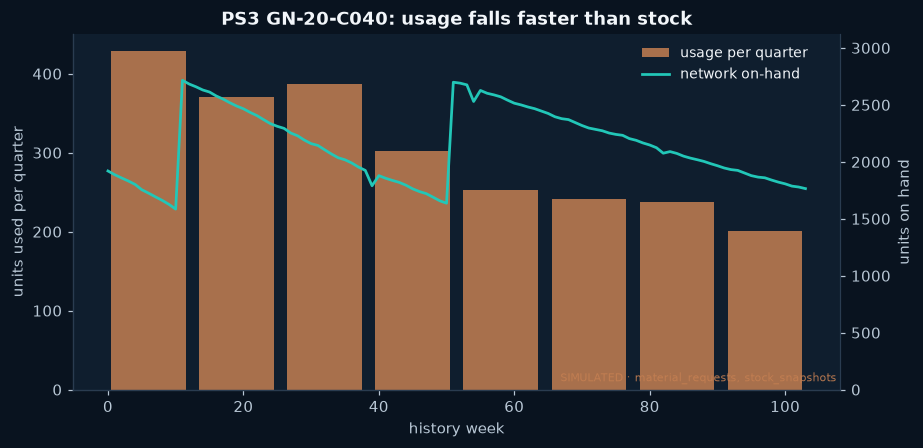

quarterly usage: [429, 371, 387, 302, 253, 242, 238, 201]


,pn,description,part_class,prior_52w_qty,recent_52w_qty,recent_vs_prior,network_on_hand,weeks_cover_at_recent_rate,on_hand_value_aed,planted
4,GN-20-C040,Self-locking nut kit,C,1489.0,934.0,0.63,1765.0,98.3,238293.0,PS3


In [15]:
pn3 = PS["PS3"]
u = q(f"select week // 13 as quarter, sum(qty) as usage from material_requests where pn = '{pn3}' group by 1 order by 1")
oh = q(f"select week, sum(on_hand) as on_hand from stock_snapshots where pn = '{pn3}' group by 1 order by 1")
fig, ax = plt.subplots()
ax.bar(u.quarter * 13 + 6, u.usage, width=11, color=COPPER, alpha=0.85, label="usage per quarter")
ax2 = ax.twinx(); ax2.plot(oh.week, oh.on_hand, color=TEAL, lw=1.8, label="network on-hand")
ax2.spines["right"].set_visible(True); ax2.tick_params(colors=TITANIUM)
ax.set(title=f"PS3 {pn3}: usage falls faster than stock", xlabel="history week", ylabel="units used per quarter")
ax2.set_ylabel("units on hand", color=TITANIUM); ax2.set_ylim(0, oh.on_hand.max() * 1.15)
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88), frameon=False); stamp(ax, "material_requests, stock_snapshots")
plt.show()
print("quarterly usage:", u.usage.astype(int).tolist())
display(sqlf("06_declining_demand_excess.sql").query("pn == @pn3"))

### PS4: a supplier change silently stretches a lead time

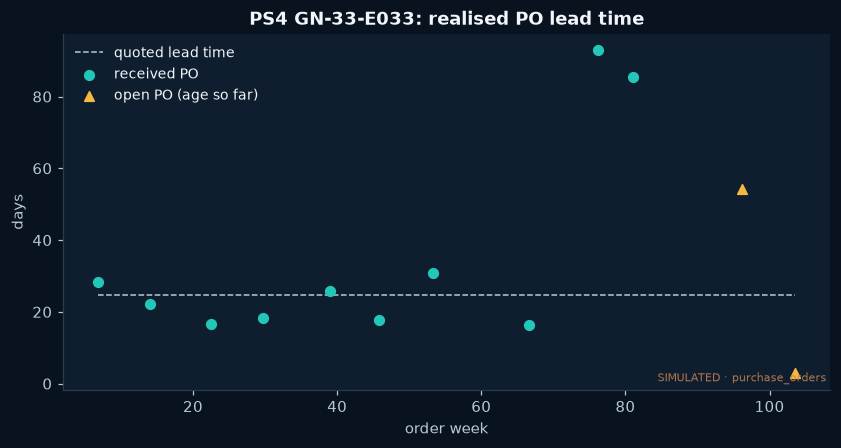

,pn,description,part_class,quoted_lead_d,earlier_pos,earlier_mean_lead_d,recent_pos,recent_open_past_due,recent_mean_lead_d,recent_vs_quoted,planted
0,GN-33-E033,Emergency light battery pack,E,24.8,8.0,22.0,3.0,1.0,77.6,3.13,PS4


In [16]:
pn4 = PS["PS4"]
po = q(f"""select po_id, order_h / 168.0 as order_week, (receipt_h - order_h) / 24.0 as lead_d,
          (due_h - order_h) / 24.0 as quoted_d, receipt_h is null as open
          from purchase_orders where pn = '{pn4}' order by order_h""")
po["lead_d"] = po.lead_d.fillna((104 * 168 - po.order_week * 168) / 24.0)
fig, ax = plt.subplots()
ax.plot(po.order_week, po.quoted_d, color=TITANIUM, ls="--", lw=1, label="quoted lead time")
ax.scatter(po.order_week[~po.open], po.lead_d[~po.open], color=TEAL, s=40, zorder=3, label="received PO")
ax.scatter(po.order_week[po.open], po.lead_d[po.open], color=AMBER, s=40, marker="^", zorder=3, label="open PO (age so far)")
ax.set(title=f"PS4 {pn4}: realised PO lead time", xlabel="order week", ylabel="days")
ax.legend(frameon=False, loc="upper left"); stamp(ax, "purchase_orders"); plt.show()
display(sqlf("05_lead_time_drift.sql"))

## Summary

* The v2 realism corrections are visible in the data: type-specific parts, no D0 consumables, fluids that never drive downtime, brake changes worked at notice, no-fault-found, and AOG recovery routes instead of an outright buy.
* The calibration band was set after a diagnosis and before any P1/P2 result. The fewest-changes candidate (V1, quote accuracy only) was applied and locked. The band ends are reported honestly: low stress reaches the AOG end, high stress the fill end.
* P0 lands inside the band in the central world on history, selection and holdout.
* Stock, owned serials, borrowed units, robbery donors, issues, repair orders, transfers and material AOG hours all balance.
* All four planted situations are visible in the public history.

Next: `02_forecasting_arena.ipynb` asks how well demand can be forecast from this history.